In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -Z -1 "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" | grep -v "__MACOSX" | grep -v "^\._" | grep "\.wav$" | wc -l

22856


In [ ]:
!unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" -d /content/MOSEI_wav

In [ ]:
!find /content/MOSEI_wav -name "._*" -delete
!rm -rf /content/MOSEI_wav/__MACOSX

In [ ]:
!find /content/MOSEI_wav -name "*.wav" | wc -l

22856


In [ ]:
import os

WAV_DIR = "/content/MOSEI_wav"

# Check top level
print("Top level:")
top = os.listdir(WAV_DIR)
print(top[:5])

# Check one level deeper
first = os.path.join(WAV_DIR, top[0])
if os.path.isdir(first):
    print(f"\nInside {top[0]}:")
    print(os.listdir(first)[:5])

Top level:
['Raw_Wav']

Inside Raw_Wav:
['BRSyH6yfDLk', 'X2leyjuolDM', 'QxU625Hn370', '3aIQUQgawaI', 'gr8mzv2xZ2s']


In [ ]:
import os, shutil

SRC_DIR  = "/content/MOSEI_wav/Raw_Wav"
FLAT_DIR = "/content/MOSEI_wav_flat"
os.makedirs(FLAT_DIR, exist_ok=True)

count = 0
for video_id in os.listdir(SRC_DIR):
    video_path = os.path.join(SRC_DIR, video_id)
    if not os.path.isdir(video_path):
        continue
    for fname in os.listdir(video_path):
        if not fname.endswith(".wav"):
            continue
        clip_id = fname.replace(".wav", "")
        src = os.path.join(video_path, fname)
        dst = os.path.join(FLAT_DIR, f"{video_id}__{clip_id}.wav")
        shutil.copy2(src, dst)
        count += 1

print(f"Done: {count} wav files flattened to {FLAT_DIR}")

Done: 22856 wav files flattened to /content/MOSEI_wav_flat


In [ ]:
import os, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import soundfile as sf
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    HubertModel,
    AutoFeatureExtractor,
    get_cosine_schedule_with_warmup,
)
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr

In [ ]:
# Config
MOSEI_BASE       = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI"
FLAT_DIR         = "/content/MOSEI_wav_flat"
ENRICHED_CSV     = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_CHECKPOINT  = "facebook/hubert-base-ls960"
SAMPLE_RATE       = 16_000
MAX_LENGTH        = int(8.0 * SAMPLE_RATE)
BATCH_SIZE        = 32
GRAD_ACCUM        = 1
MAX_EPOCHS        = 200
PATIENCE          = 10                 # decreased from 15
WARMUP_RATIO      = 0.1
SEED              = 42

# Loss weights — MSE + CCC combined
MSE_WEIGHT        = 0.5
CCC_WEIGHT        = 0.5
SENTIMENT_WEIGHT  = 1.0
EMOTION_WEIGHT    = 1.0

# LLRD — learning rates per layer group
LR_HEAD           = 3e-5   # output heads — highest lr
LR_TOP_LAYERS     = 3e-6   # top transformer layers
LR_MID_LAYERS     = 1e-6   # middle transformer layers
LR_BOTTOM_LAYERS  = 3e-7   # bottom transformer layers — lowest lr
LR_FEATURE_ENC    = 0.0    # CNN feature encoder — frozen

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
    print(f"VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device: cuda
GPU   : NVIDIA A100-SXM4-40GB
VRAM  : 42.4 GB


In [ ]:
# CCC metric (numpy — for evaluation)
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _    = pearsonr(y_true, y_pred)
    std_true  = np.std(y_true)
    std_pred  = np.std(y_pred)
    mean_true = np.mean(y_true)
    mean_pred = np.mean(y_pred)
    numerator   = 2.0 * rho * std_true * std_pred
    denominator = std_true**2 + std_pred**2 + (mean_true - mean_pred)**2
    return float(numerator / denominator if denominator > 1e-8 else 0.0), float(rho)

In [ ]:
# CCC loss (torch — for training)
def ccc_loss_single(pred, target):
    mean_p = pred.mean()
    mean_t = target.mean()
    std_p  = pred.std()  + 1e-8
    std_t  = target.std() + 1e-8
    cov    = ((pred - mean_p) * (target - mean_t)).mean()
    denom  = std_p**2 + std_t**2 + (mean_p - mean_t)**2 + 1e-8
    return 1.0 - (2.0 * cov) / denom

In [ ]:
def combined_loss(pred, target, is_emotion=False):
    """
    MSE + CCC combined loss (Option 2).
    MSE gets the scale right, CCC gets the pattern right.
    """
    if is_emotion:
        # Per-emotion MSE (no weighting — weights were hurting performance)
        mse = F.mse_loss(pred, target)

        # Per-emotion CCC — unweighted, averaged across 6 emotions
        ccc_vals = torch.stack([
            ccc_loss_single(pred[:, i], target[:, i])
            for i in range(pred.shape[1])
        ])
        ccc = ccc_vals.mean()
    else:
        # Sentiment — single scalar
        mse = F.mse_loss(pred, target)
        ccc = ccc_loss_single(pred, target)

    return MSE_WEIGHT * mse + CCC_WEIGHT * ccc

In [ ]:
# Label mapping helpers
def sentiment_to_class(score):
    if score > 0:   return "Positive"
    elif score < 0: return "Negative"
    else:           return "Neutral"

def emotion_vector_to_labels(pred_vector, threshold=EMOTION_THRESHOLD):
    dominant = EMOTION_COLS[int(np.argmax(pred_vector))]
    present  = [EMOTION_COLS[i] for i, v in enumerate(pred_vector) if v >= threshold]
    return dominant, present

In [ ]:
# Cell 2: Load & validate labels
df = pd.read_csv(ENRICHED_CSV)
print(f"Loaded {len(df)} rows")

df["wav_path"] = df.apply(
    lambda r: f"{FLAT_DIR}/{r['video_id']}__{int(r['clip_id'])}.wav", axis=1
)
before = len(df)
df = df[df["wav_path"].apply(os.path.exists)].copy()
print(f"Dropped {before - len(df)} missing wavs  |  Remaining: {len(df)}")

df["sentiment_norm"] = df["sentiment"].clip(-3, 3) / 3.0
for col in EMOTION_COLS:
    df[col] = df[col].clip(0, 1)

train_df = df[df["mode"] == "train"].reset_index(drop=True)
val_df   = df[df["mode"] == "valid"].reset_index(drop=True)
test_df  = df[df["mode"] == "test"].reset_index(drop=True)
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

# Emotion distribution check
print(f"\nEmotion score means (train):")
for col in EMOTION_COLS:
    nonzero = (train_df[col] > 0.1).sum()
    print(f"  {col:<10}: mean={train_df[col].mean():.3f}  non-zero={nonzero} ({nonzero/len(train_df)*100:.1f}%)")

Loaded 19970 rows
Dropped 0 missing wavs  |  Remaining: 19970
Train: 14179  |  Val: 1671  |  Test: 4120

Emotion score means (train):
  happy     : mean=0.371  non-zero=7605 (53.6%)
  sad       : mean=0.149  non-zero=3696 (26.1%)
  anger     : mean=0.135  non-zero=2989 (21.1%)
  fear      : mean=0.047  non-zero=1415 (10.0%)
  disgust   : mean=0.107  non-zero=2512 (17.7%)
  surprise  : mean=0.041  non-zero=1175 (8.3%)


In [ ]:
# Feature extractor & Dataset
feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_CHECKPOINT)

class MOSEIDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            audio, _ = sf.read(row["wav_path"], dtype="float32")
        except Exception:
            audio = np.zeros(MAX_LENGTH, dtype=np.float32)
        if len(audio) > MAX_LENGTH:
            audio = audio[:MAX_LENGTH]
        sentiment = float(row["sentiment_norm"])
        emotions  = [float(row[c]) for c in EMOTION_COLS]
        return audio, sentiment, emotions

def collate_fn(batch):
    audios, sentiments, emotions = zip(*batch)
    inputs = feature_extractor(
        list(audios), sampling_rate=SAMPLE_RATE,
        max_length=MAX_LENGTH, truncation=True,
        padding="max_length", return_tensors="pt",
    )
    inputs["sentiment_labels"] = torch.tensor(sentiments, dtype=torch.float32)
    inputs["emotion_labels"]   = torch.tensor(emotions,   dtype=torch.float32)
    return inputs

train_loader = DataLoader(MOSEIDataset(train_df), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=8, collate_fn=collate_fn)
val_loader   = DataLoader(MOSEIDataset(val_df),   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn)
test_loader  = DataLoader(MOSEIDataset(test_df),  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn)
print(f"Batches — train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")

Batches — train: 444  val: 53  test: 129


In [ ]:
# Model with attention pooling
class HuBERTMultiTask(nn.Module):
    def __init__(self, checkpoint):
        super().__init__()
        self.hubert  = HubertModel.from_pretrained(checkpoint)
        hidden       = self.hubert.config.hidden_size   # 768
        self.dropout = nn.Dropout(0.1) # changed from 0.1 from first 20 epochs

        # Attention pooling — learns which frames matter most
        # Instead of mean pooling which weights all frames equally
        self.attn_pool = nn.Linear(hidden, 1)

        # Sentiment head: 768 → 256 → 1  scalar [-1, 1]
        self.sentiment_head = nn.Sequential(
            nn.Linear(hidden, 256),
            nn.GELU(),
            nn.Dropout(0.2), # changed from 0.1 from first 20 epochs
            nn.Linear(256, 1),
            nn.Tanh(),
        )

        # Emotion head: 768 → 256 → 6  vector [0, 1]
        self.emotion_head = nn.Sequential(
            nn.Linear(hidden, 256),
            nn.GELU(),
            nn.Dropout(0.2), # changed from 0.1 from first 20 epochs
            nn.Linear(256, 6),
            nn.Sigmoid(),
        )

    def attention_pool(self, hidden_states):
        weights = F.softmax(self.attn_pool(hidden_states), dim=1)  # (B, T, 1)
        return (weights * hidden_states).sum(dim=1)                 # (B, 768)

    def freeze_feature_encoder(self):
        for param in self.hubert.feature_extractor.parameters():
            param.requires_grad = False

    def forward(self, input_values,
                sentiment_labels=None, emotion_labels=None):
        outputs        = self.hubert(input_values=input_values)
        hidden_states  = outputs.last_hidden_state       # (B, T, 768)

        # Attention pooling instead of mean pooling
        pooled         = self.attention_pool(hidden_states)
        pooled         = self.dropout(pooled)

        sentiment_pred = self.sentiment_head(pooled).squeeze(-1)   # (B,)
        emotion_pred   = self.emotion_head(pooled)                  # (B, 6)

        loss = None
        if sentiment_labels is not None and emotion_labels is not None:
            sent_loss = combined_loss(sentiment_pred, sentiment_labels, is_emotion=False)
            emot_loss = combined_loss(emotion_pred,   emotion_labels,   is_emotion=True)
            loss = SENTIMENT_WEIGHT * sent_loss + EMOTION_WEIGHT * emot_loss

        return loss, sentiment_pred, emotion_pred


model = HuBERTMultiTask(MODEL_CHECKPOINT).to(device)
model.freeze_feature_encoder()
print(f"Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Trainable params: 90,567,560


In [ ]:
# LLRD optimizer
# HuBERT-base has 12 transformer layers (0-11)
# Lower layers = low-level acoustic features → small lr
# Higher layers = task-specific features   → larger lr
# Heads                                    → largest lr

num_layers   = len(model.hubert.encoder.layers)   # 12
third        = num_layers // 3                     # 4 layers per group

param_groups = []

# Feature encoder — frozen (lr=0)
param_groups.append({
    "params": model.hubert.feature_extractor.parameters(),
    "lr": LR_FEATURE_ENC,
    "name": "feature_encoder"
})

# Bottom transformer layers (0-3) — smallest lr
param_groups.append({
    "params": [p for i, layer in enumerate(model.hubert.encoder.layers)
               if i < third for p in layer.parameters()],
    "lr": LR_BOTTOM_LAYERS,
    "name": "bottom_layers"
})

# Middle transformer layers (4-7)
param_groups.append({
    "params": [p for i, layer in enumerate(model.hubert.encoder.layers)
               if third <= i < 2 * third for p in layer.parameters()],
    "lr": LR_MID_LAYERS,
    "name": "mid_layers"
})

# Top transformer layers (8-11) — larger lr
param_groups.append({
    "params": [p for i, layer in enumerate(model.hubert.encoder.layers)
               if i >= 2 * third for p in layer.parameters()],
    "lr": LR_TOP_LAYERS,
    "name": "top_layers"
})

# Attention pooling + output heads — highest lr
param_groups.append({
    "params": list(model.attn_pool.parameters()) +
              list(model.sentiment_head.parameters()) +
              list(model.emotion_head.parameters()),
    "lr": LR_HEAD,
    "name": "heads"
})

optimizer = AdamW(param_groups, weight_decay=0.01)

print("LLRD parameter groups:")
for g in param_groups:
    n_params = sum(p.numel() for p in g["params"] if p.requires_grad)
    print(f"  {g['name']:<20}: lr={g['lr']:.0e}  params={n_params:,}")

total_steps = (len(train_loader) // GRAD_ACCUM) * MAX_EPOCHS
scheduler   = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps,
)
print(f"\nTotal steps: {total_steps}  |  Warmup: {int(total_steps * WARMUP_RATIO)}")

LLRD parameter groups:
  feature_encoder     : lr=0e+00  params=0
  bottom_layers       : lr=3e-07  params=28,351,488
  mid_layers          : lr=1e-06  params=28,351,488
  top_layers          : lr=3e-06  params=28,351,488
  heads               : lr=3e-05  params=396,296

Total steps: 88800  |  Warmup: 8880


In [ ]:
# Resume from checkpoint
CHECKPOINT = f"{OUTPUT_DIR}/training_state.pt"

if os.path.exists(CHECKPOINT):
    print("Found checkpoint — resuming...")
    state = torch.load(CHECKPOINT, map_location=device)

    model.load_state_dict(
        torch.load(f"{OUTPUT_DIR}/best_model.pt", map_location=device)
    )
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])

    best_avg_ccc   = state["best_avg_ccc"]
    best_epoch     = state["best_epoch"]
    patience_count = state["patience_count"]
    history        = state["history"]
    start_epoch    = state["epoch"] + 1

    print(f"  Resumed from epoch {state['epoch']}")
    print(f"  Best avg CCC so far: {best_avg_ccc:.4f} @ epoch {best_epoch}")
    print(f"  Patience count: {patience_count}")
else:
    print("No checkpoint found — starting fresh")
    best_avg_ccc, patience_count, best_epoch = -1.0, 0, 0
    start_epoch = 1
    history = {
        "train_loss":    [],
        "val_loss":      [],
        "sent_ccc":      [],
        "sent_plcc":     [],
        "sent_mae":      [],
        "mean_emot_ccc": [],
        "emot_mae":      [],
    }

Found checkpoint — resuming...
  Resumed from epoch 20
  Best avg CCC so far: 0.4070 @ epoch 20
  Patience count: 0


In [ ]:
# Eval helper
def evaluate(loader):
    model.eval()
    all_sent_pred, all_sent_true = [], []
    all_emot_pred, all_emot_true = [], []
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            iv   = batch["input_values"].to(device)
            slbl = batch["sentiment_labels"].to(device)
            elbl = batch["emotion_labels"].to(device)

            loss, sent_pred, emot_pred = model(iv, slbl, elbl)
            total_loss += loss.item()

            all_sent_pred.extend((sent_pred.cpu().numpy() * 3).tolist())
            all_sent_true.extend((slbl.cpu().numpy()      * 3).tolist())
            all_emot_pred.extend(emot_pred.cpu().numpy().tolist())
            all_emot_true.extend(elbl.cpu().numpy().tolist())

    avg_loss            = total_loss / len(loader)
    sent_ccc_val, sent_plcc = ccc_np(all_sent_true, all_sent_pred)
    sent_mae            = mean_absolute_error(all_sent_true, all_sent_pred)

    all_emot_pred   = np.array(all_emot_pred)
    all_emot_true   = np.array(all_emot_true)
    emot_ccc_scores = [ccc_np(all_emot_true[:, i], all_emot_pred[:, i])[0]
                       for i in range(len(EMOTION_COLS))]
    mean_emot_ccc   = float(np.mean(emot_ccc_scores))
    emot_mae        = mean_absolute_error(all_emot_true.flatten(), all_emot_pred.flatten())

    return (avg_loss,
            sent_ccc_val, sent_plcc, sent_mae,
            mean_emot_ccc, emot_ccc_scores, emot_mae,
            all_sent_pred, all_sent_true,
            all_emot_pred, all_emot_true)

In [ ]:
# Training loop
# history = {
#     "train_loss":    [],
#     "val_loss":      [],
#     "sent_ccc":      [],
#     "sent_plcc":     [],
#     "sent_mae":      [],
#     "mean_emot_ccc": [],
#     "emot_mae":      [],
# }
# best_avg_ccc, patience_count, best_epoch = -1.0, 0, 0

print(f"\n{'Ep':>4} {'TrLoss':>8} {'VlLoss':>8} "
      f"{'SentCCC':>9} {'SentPLCC':>9} {'SentMAE':>9} "
      f"{'EmotCCC':>9} {'Pat':>5}")
print("─" * 72)

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    model.train()
    tr_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        iv   = batch["input_values"].to(device)
        slbl = batch["sentiment_labels"].to(device)
        elbl = batch["emotion_labels"].to(device)

        loss, _, _ = model(iv, slbl, elbl)
        (loss / GRAD_ACCUM).backward()
        tr_loss += loss.item()

        if (step + 1) % GRAD_ACCUM == 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

    tr_loss /= len(train_loader)

    (vl_loss,
     sent_ccc_val, sent_plcc, sent_mae,
     mean_emot_ccc, _, emot_mae,
     _, _, _, _) = evaluate(val_loader)

    avg_ccc = (sent_ccc_val + mean_emot_ccc) / 2.0

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["sent_ccc"].append(sent_ccc_val)
    history["sent_plcc"].append(sent_plcc)
    history["sent_mae"].append(sent_mae)
    history["mean_emot_ccc"].append(mean_emot_ccc)
    history["emot_mae"].append(emot_mae)

    improved = avg_ccc > best_avg_ccc
    if improved:
        best_avg_ccc, best_epoch, patience_count = avg_ccc, epoch, 0
        torch.save(model.state_dict(), f"{OUTPUT_DIR}/best_model.pt")
        feature_extractor.save_pretrained(f"{OUTPUT_DIR}/best")

        torch.save({
            "epoch":          epoch,
            "best_avg_ccc":   best_avg_ccc,
            "best_epoch":     best_epoch,
            "patience_count": patience_count,
            "optimizer":      optimizer.state_dict(),
            "scheduler":      scheduler.state_dict(),
            "history":        history,
        }, f"{OUTPUT_DIR}/training_state.pt")
        print(f"  → Checkpoint saved to Drive @ epoch {epoch}")
    else:
        patience_count += 1

    flag = " ✓" if improved else ""
    print(f"{epoch:>4} {tr_loss:>8.4f} {vl_loss:>8.4f} "
          f"{sent_ccc_val:>9.4f} {sent_plcc:>9.4f} {sent_mae:>9.4f} "
          f"{mean_emot_ccc:>9.4f} {patience_count:>5}{flag}")

    if patience_count >= PATIENCE:
        print(f"\nEarly stop @ epoch {epoch} — best avg CCC {best_avg_ccc:.4f} @ epoch {best_epoch}")
        break

    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


  Ep   TrLoss   VlLoss   SentCCC  SentPLCC   SentMAE   EmotCCC   Pat
────────────────────────────────────────────────────────────────────────
  21   0.4930   0.8313    0.5125    0.5340    0.7367    0.2737     1
  22   0.4694   0.8253    0.5094    0.5202    0.7581    0.2719     2
  23   0.4480   0.8381    0.4850    0.4989    0.7125    0.2433     3
  24   0.4287   0.8316    0.4897    0.5018    0.7183    0.2675     4


KeyboardInterrupt: 

In [ ]:
# Test evaluation
print("\nLoading best model for test evaluation…")
model.load_state_dict(torch.load(f"{OUTPUT_DIR}/best_model.pt"))

(_, sent_ccc_val, sent_plcc, sent_mae,
 mean_emot_ccc, emot_ccc_scores, emot_mae,
 sent_preds, sent_true,
 emot_preds, emot_true) = evaluate(test_loader)

print(f"\n── Sentiment (scale -3 to 3) ───────────────────────────────────")
print(f"  CCC  : {sent_ccc_val:.4f}   ← primary metric (pattern + accuracy)")
print(f"  PLCC : {sent_plcc:.4f}         ← Pearson (pattern only)")
print(f"  MAE  : {sent_mae:.4f}           ← absolute error")

print(f"\n── Emotion vector ──────────────────────────────────────────────")
for i, col in enumerate(EMOTION_COLS):
    emot_mae_i = mean_absolute_error(emot_true[:, i], emot_preds[:, i])
    print(f"  {col:<10}: CCC {emot_ccc_scores[i]:>7.4f}   MAE {emot_mae_i:.4f}")
print(f"  {'Mean':<10}: CCC {mean_emot_ccc:>7.4f}   MAE {emot_mae:.4f}")
print(f"\n  Overall avg CCC: {(sent_ccc_val + mean_emot_ccc) / 2:.4f}")


Loading best model for test evaluation…

── Sentiment (scale -3 to 3) ───────────────────────────────────
  CCC  : 0.5756   ← primary metric (pattern + accuracy)
  PLCC : 0.5811         ← Pearson (pattern only)
  MAE  : 0.7715           ← absolute error

── Emotion vector ──────────────────────────────────────────────
  happy     : CCC  0.4450   MAE 0.2985
  sad       : CCC  0.3012   MAE 0.1906
  anger     : CCC  0.3516   MAE 0.1717
  fear      : CCC  0.1535   MAE 0.1052
  disgust   : CCC  0.4080   MAE 0.1377
  surprise  : CCC  0.1569   MAE 0.1078
  Mean      : CCC  0.3027   MAE 0.1686

  Overall avg CCC: 0.4391


In [ ]:
# Sample inference
print("\n── Sample predictions (first 10 test samples) ──────────────────")
print(f"{'#':<4} {'TrueSent':>9} {'PredSent':>9} {'Class':>10} | "
      + "  ".join(f"{c[:4]:>6}" for c in EMOTION_COLS)
      + "  Dominant   Present")
print("─" * 115)

for i in range(min(10, len(sent_preds))):
    dominant, present = emotion_vector_to_labels(emot_preds[i])
    sent_class        = sentiment_to_class(sent_preds[i])
    emot_row          = "  ".join(f"{emot_preds[i][j]:>6.3f}" for j in range(6))
    present_str       = ",".join(present) if present else "none"
    print(f"{i+1:<4} {sent_true[i]:>9.3f} {sent_preds[i]:>9.3f} {sent_class:>10} | "
          f"{emot_row}  {dominant:<10} {present_str}")


── Sample predictions (first 10 test samples) ──────────────────
#     TrueSent  PredSent      Class |   happ     sad    ange    fear    disg    surp  Dominant   Present
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
1        0.333     1.012   Positive |  0.450   0.006   0.020   0.005   0.001   0.005  happy      none
2       -1.000    -1.679   Negative |  0.004   0.735   0.652   0.050   0.563   0.022  sad        sad,anger,disgust
3        0.000    -0.376   Negative |  0.012   0.455   0.145   0.006   0.047   0.058  sad        none
4        1.333     1.926   Positive |  0.998   0.000   0.000   0.027   0.000   0.001  happy      happy
5        1.000     1.385   Positive |  0.996   0.001   0.006   0.450   0.005   0.009  happy      happy
6        0.333     0.688   Positive |  0.961   0.001   0.010   0.059   0.002   0.004  happy      happy
7        0.000     0.814   Positive |  0.991   0.000   0.000   0.000   0.000   0.000 

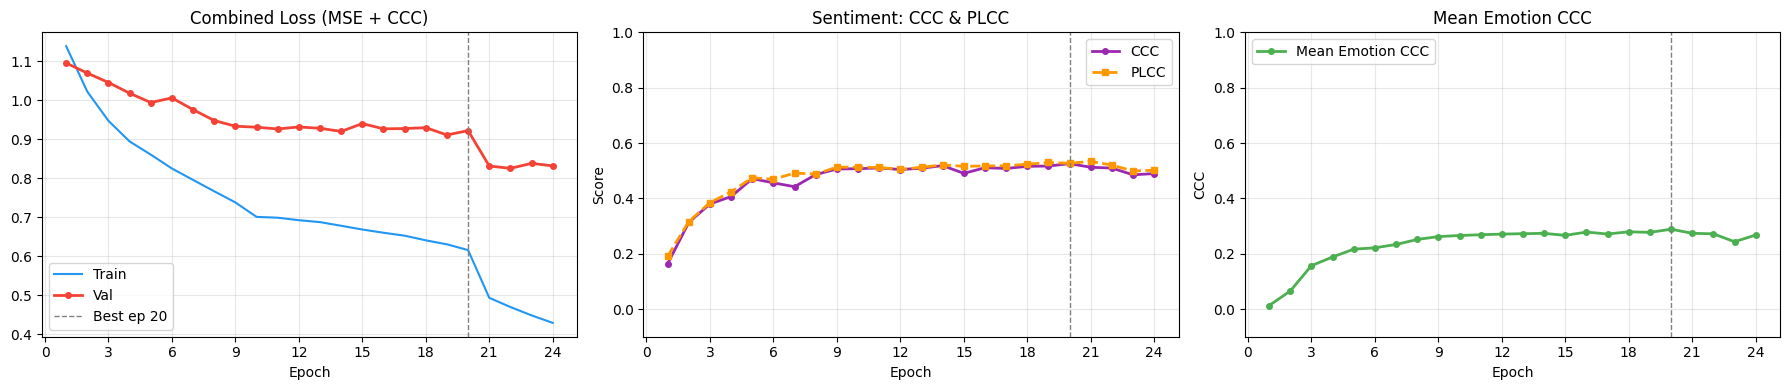

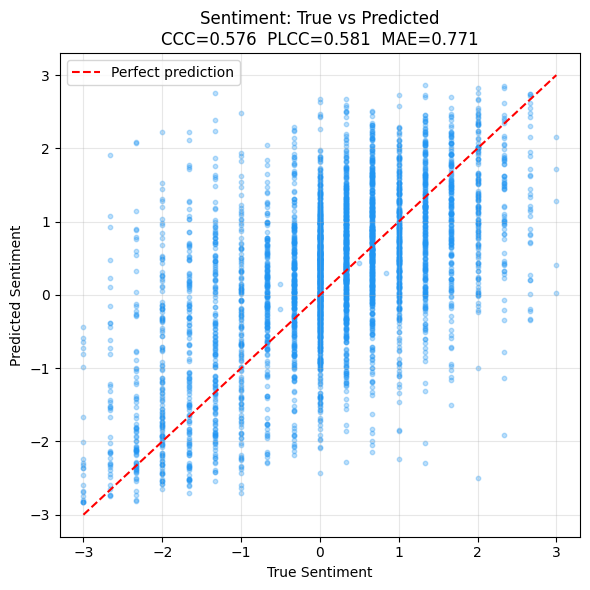

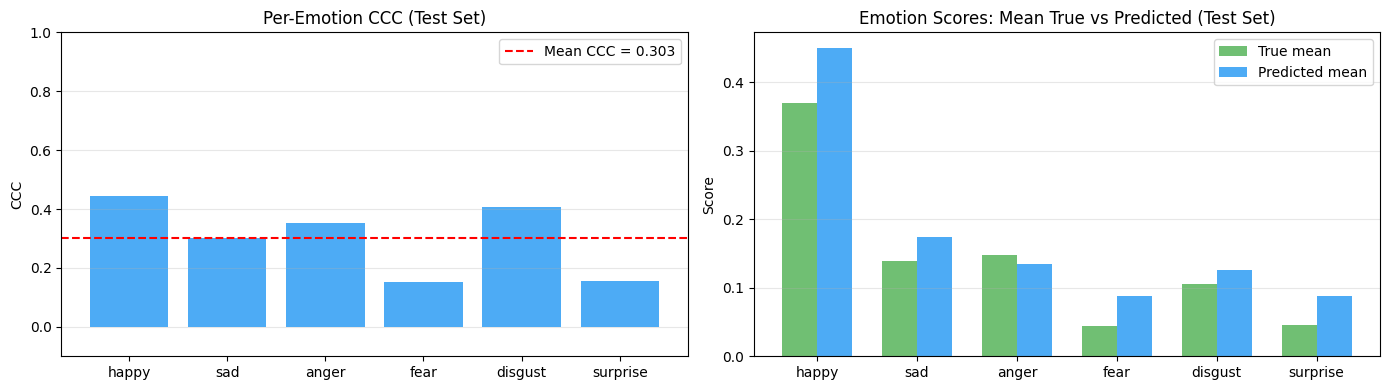


All outputs saved to: /content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd


In [ ]:
# Plots
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Loss
axes[0].plot(epochs_ran, history["train_loss"], label="Train", color="#2196F3", linewidth=1.5)
axes[0].plot(epochs_ran, history["val_loss"],   label="Val",   color="#F44336", linewidth=2, marker="o", markersize=4)
axes[0].axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"Best ep {best_epoch}")
axes[0].set_title("Combined Loss (MSE + CCC)")
axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Sentiment CCC & PLCC
axes[1].plot(epochs_ran, history["sent_ccc"],  label="CCC",  color="#9C27B0", linewidth=2, marker="o", markersize=4)
axes[1].plot(epochs_ran, history["sent_plcc"], label="PLCC", color="#FF9800", linewidth=2, marker="s", markersize=4, linestyle="--")
axes[1].axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Sentiment: CCC & PLCC")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score"); axes[1].set_ylim(-0.1, 1.0)
axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Emotion CCC
axes[2].plot(epochs_ran, history["mean_emot_ccc"], label="Mean Emotion CCC", color="#4CAF50", linewidth=2, marker="o", markersize=4)
axes[2].axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
axes[2].set_title("Mean Emotion CCC")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("CCC"); axes[2].set_ylim(-0.1, 1.0)
axes[2].legend(); axes[2].grid(True, alpha=0.3)
axes[2].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150)
plt.show()

# Sentiment scatter
fig2, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sent_true, sent_preds, alpha=0.3, s=10, color="#2196F3")
ax.plot([-3, 3], [-3, 3], "r--", linewidth=1.5, label="Perfect prediction")
ax.set_xlabel("True Sentiment"); ax.set_ylabel("Predicted Sentiment")
ax.set_title(f"Sentiment: True vs Predicted\nCCC={sent_ccc_val:.3f}  PLCC={sent_plcc:.3f}  MAE={sent_mae:.3f}")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sentiment_scatter.png", dpi=150)
plt.show()

# Per-emotion analysis
fig3, axes3 = plt.subplots(1, 2, figsize=(14, 4))

axes3[0].bar(EMOTION_COLS, emot_ccc_scores, color="#2196F3", alpha=0.8)
axes3[0].axhline(mean_emot_ccc, color="red", linestyle="--", linewidth=1.5,
                 label=f"Mean CCC = {mean_emot_ccc:.3f}")
axes3[0].set_title("Per-Emotion CCC (Test Set)")
axes3[0].set_ylabel("CCC"); axes3[0].set_ylim(-0.1, 1.0)
axes3[0].legend(); axes3[0].grid(True, alpha=0.3, axis="y")

x = np.arange(len(EMOTION_COLS))
w = 0.35
axes3[1].bar(x - w/2, emot_true.mean(axis=0),  w, label="True mean",      color="#4CAF50", alpha=0.8)
axes3[1].bar(x + w/2, emot_preds.mean(axis=0), w, label="Predicted mean", color="#2196F3", alpha=0.8)
axes3[1].set_xticks(x); axes3[1].set_xticklabels(EMOTION_COLS)
axes3[1].set_title("Emotion Scores: Mean True vs Predicted (Test Set)")
axes3[1].set_ylabel("Score"); axes3[1].legend(); axes3[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/emotion_analysis.png", dpi=150)
plt.show()

print(f"\nAll outputs saved to: {OUTPUT_DIR}")